## Praktikum 2
##### Erweiterte Operationen auf Gesichtern

In diesem Praktikum betrachten wir weitere Operationen auf Gesichtern und trainieren erste kleine Netzwerke zur Gesichtserkennung.

<div style="padding: 10px; border-left: 5px solid #B777FA; background-color: #5C18FA; border-radius: 4px">
  🐍 Bitte nutzen Sie die virtuelle Umgebung: <b>DLACV_2526</b>
</div>

In [8]:
# imports
import cv2, dlib
import numpy as np
from utils.dataPath import DATA_PATH
from utils.dataPath import MODEL_PATH
import utils.faceUtils as faceUtils
import utils.faceBlendCommon as fbc

from cv2.typing import MatLike
import numpy.typing as npt
from typing import List, Tuple

import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.figsize'] = (6.0,6.0)
matplotlib.rcParams['image.cmap'] = 'gray'

In [9]:
# Konstanten
PREDICTOR_PATH = MODEL_PATH + "shape_predictor_68_face_landmarks.dat"
RESIZE_HEIGHT = 480
NUM_FRAMES_FOR_FPS = 100
SKIP_FRAMES = 1
WIN_NAME = "Bug-Eyes mit stabilisiertem Landmarkendetektor"
CAP_INDEX = 0  # Kamera-Index oder Videopfad

# Detektoren initialisieren
detector = dlib.get_frontal_face_detector()
landmarkDetector = dlib.shape_predictor(PREDICTOR_PATH)

#### Bug-Eyes-Filter
Ziel hier ist es, einen Bug-Eyes-Filter (Käferaugen) zu implementieren. Dafür müssen wir eine Barrel-Distortion implementieren, nachdem wir die Region of Interest (ROI) aus dem Bild gefunden haben.

<center>
<img src="data/images/bugEyeExample.jpg" width=1000>
</center>

<center>
<img src="data/images/radial-distortions.png" width=1000>
</center>

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 2.6:</b><br>
  • Implementieren Sie die Methode <code>barrel</code> ohne die Verwendung von <code>cv2</code>.<br>Eine Ausnahme ist die Funktion <code>cv2.remap</code>.
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis:</b></i> Nutzen Sie die folgende Formel zum Berechnen der Barrel-Distortion.
</div>

$dr = k * r * cos(pi * r)$

In [10]:
def barrel(src: MatLike, k: float) -> MatLike:
  """Applies a barrel filter in the center of src with k as the bulge amount

  Parameters
  ----------
  src : MatLike
    Input image
  k : float
    Bulge amount

  Returns
  -------
  MatLike
    Bulged image
  """
  if src is None or src.size == 0:
    return src
  
  w = src.shape[1]
  h = src.shape[0]

  if h <= 1 or w <= 1:
    return src

  # Meshgrid des Zielbildes erzeugen
  x, y = np.meshgrid(np.arange(w), np.arange(h))


  
  # x und y normalisieren
  x = np.float32(x)/float(w)-0.5
  y = np.float32(y)/float(h)-0.5

  # Radius-Distanz vom Mittelpunkt
  r = np.sqrt(np.square(x) + np.square(y))
  r_safe = np.where(r == 0, 1e-8, r) 

  # Implementierung der obigen Formel
  dr = k* r * np.cos(np.pi*r)
  

  
  # Alles außerhalb des maximalen Radius' dr wird auf 0 gesetzt
  maxR = 0.5
  dr = np.where(r > maxR, 0, dr)
    
  # Wir müssen inverses Mapping an die Methode remap übergeben
  # Deshalb das Minus vor dr
  rn = r - dr    

  # Die Verzerrung auf das Grid anwenden
  xd = (rn* x)/r_safe
  yd = (rn*y)/r_safe
    
  # Koordinaten de-normalisieren  
  xd = float(w) * ( xd + 0.5 )
  yd = float(h) * ( yd + 0.5 )

  xd = np.float32(xd)
  yd = np.float32(yd)

  # Warp anwenden
  dst = cv2.remap(src, xd, yd, cv2.INTER_CUBIC, borderMode=cv2.BORDER_REFLECT)
  return dst

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 2.7:</b><br>
  • Implementieren Sie die Methode <code>bugEyes</code> ohne die Verwendung von <code>cv2</code>, indem Sie die ROI herausfinden und die Funktion <code>barrel</code> darauf anwenden.
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis:</b></i> Überprüfen Sie, welche Landmarken-Indizes für die ROI verwendet werden müssen. Vergessen Sie außerdem nicht den Radius in Ihre Berechnung mit einzubringen.
</div>

In [11]:
def bugEyes(im: MatLike, points: List[Tuple[float, float]], bulgeAmount: float = 0.75, radius: float = 30) -> MatLike:
  """Applies a barrel filter on both eyes

  Parameters
  ----------
  im : MatLike
    Input image
  points : List[Tuple[float, float]]
    Points generated by a 68 point face landmark detector
  bulgeAmount: float
    Amount to bulge each eye
  radius : float
    Radius of the filter on each eye
  
  Returns
  -------
  MatLike
    Bug eyed image
  """
  output = np.copy(im)
  h, w = im.shape[:2]

  # Über alle Gesichter iterieren
  for i in range(len(points) // 68):
    landmarks = points[i*68 : (i + 1) * 68]  # Gesicht aus Punkten erhalten

    roiEyeLeft = landmarks[36:42]  # Landmarken 36-41
    roiEyeRight = landmarks[42:48]  # Landmarken 42-47

    for roiEye in (roiEyeLeft, roiEyeRight):
      # Augenmittelpunkt aus den Landmarken bestimmen
      cx, cy = np.mean(roiEye, axis=0)

      # ROI um den Mittelpunkt ausschneiden (auf Bildgrenzen beschränkt)
      x1 = max(int(cx - radius), 0)
      y1 = max(int(cy - radius), 0)
      x2 = min(int(cx + radius), w)
      y2 = min(int(cy + radius), h)

      roi = output[y1:y2, x1:x2]

      # Barrel-Filter auf die ROI anwenden und zurückschreiben
      output[y1:y2, x1:x2] = barrel(roi, bulgeAmount)

  return output

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 2.8:</b><br>
  • Lesen Sie das Bild <code>data/images/ted_cruz.jpg</code> ein.<br>
  • Wenden Sie Ihren Bug-Eyes-Filter auf das Bild an.<br>
  • Geben Sie beide Bilder aus.
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis:</b></i> Überprüfen Sie das Format und die Kanäle, in denen das Bild eingelesen wird.<br>Sollte das Bild nicht richtig aussehen, ist möglicherweise die Reihenfolge der Farbkanäle falsch.
</div>

points[(149, 328), (147, 366), (148, 402), (152, 440), (160, 477), (177, 510), (202, 540), (232, 565), (270, 575), (315, 570), (361, 551), (402, 524), (434, 490), (452, 449), (461, 407), (465, 368), (466, 327), (160, 303), (170, 281), (192, 270), (219, 269), (243, 278), (300, 278), (331, 269), (363, 269), (394, 278), (416, 300), (272, 313), (270, 345), (267, 377), (265, 410), (238, 417), (253, 426), (269, 434), (290, 426), (308, 417), (188, 321), (203, 311), (223, 311), (241, 322), (222, 324), (203, 325), (322, 323), (341, 312), (361, 311), (378, 321), (361, 326), (341, 325), (212, 458), (235, 454), (256, 453), (274, 456), (293, 452), (322, 453), (354, 458), (324, 481), (295, 490), (274, 491), (255, 489), (234, 481), (222, 460), (256, 465), (274, 466), (294, 463), (344, 460), (294, 473), (274, 474), (256, 472)]
[[149. 328.]
 [147. 366.]
 [148. 402.]
 [152. 440.]
 [160. 477.]
 [177. 510.]
 [202. 540.]
 [232. 565.]
 [270. 575.]
 [315. 570.]
 [361. 551.]
 [402. 524.]
 [434. 490.]
 [452. 4

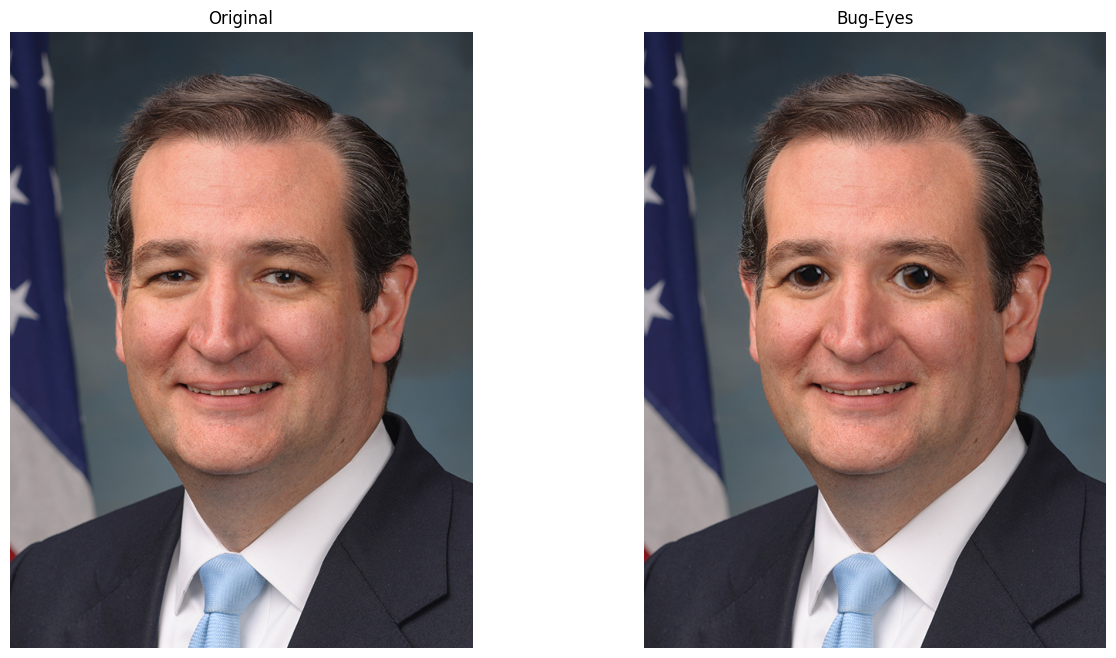

In [12]:
# Bilder einlesen und in RGB konvertieren
img = cv2.imread("data/images/ted_cruz.jpg")
img = cv2.cvtColor(img,cv2.COLOR_RGBA2BGR)

# Gesichter und Landmarken detektieren
det = detector(img,1)

for i in range(0, len(det)):
  newRect = dlib.rectangle(int(det[i].left()),
                          int(det[i].top()),
                          int(det[i].right()),
                          int(det[i].bottom()))

landmarks = landmarkDetector(img,newRect).parts()
print(landmarks)
# Punkte konvertieren
points = np.array([(p.x, p.y) for p in landmarks], dtype=np.float32)

# Punkte auf Bildgrenzen beschränken
capH, capW, _ = img.shape
pointsClipped = np.clip(points, [0, 0], [capW, capH])
print(pointsClipped)

# Filter anwenden
dst_rgb = bugEyes(img,pointsClipped)

# Anzeigen
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

axes[0].imshow(img)
axes[0].axis('off')
axes[0].set_title('Original')

axes[1].imshow(dst_rgb)
axes[1].axis('off')
axes[1].set_title('Bug-Eyes')

plt.show()

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 2.9:</b><br>
  • Überprüfen Sie den (stabilisierten) Bug-Eyes-Filter mit einer Webcam oder einem Video.
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis 1:</b></i> Nutzen Sie die Tasten <code>S</code>, <code>D</code> und <code>L</code>, um verschiedene Bilder zu erzeugen.<br>
💡 <i><b>Hinweis 2:</b></i> Es kann zu unerwünschten Ergebnissen kommen, wenn der Stabilisator immer aktiv ist. Überprüfen Sie, wann es sich lohnt, diesen einzuschalten.
</div>

In [13]:
# Video-Capture initialisieren
cap = cv2.VideoCapture(CAP_INDEX)

if(cap.isOpened()==False):
  print("Video kann nicht geladen werden.")
  exit()

# Frame holen
ret, imPrev = cap.read()

# Dimensionen berechnen
if imPrev.any != None:
  capH, capW, _ = imPrev.shape

# In Grauwert umwandeln
imGrayPrev = cv2.cvtColor(imPrev, cv2.COLOR_BGR2GRAY)

# Parameter initialisieren
pointsDetectedCur=[]
pointsDetectedPrev=[]

totalEyeDistance = 0
avgEyeDistance = 100
fps = 10
enableStabilizer = False
showLandmarks = False
enableDetector = True
frameCount = 0

In [ ]:
print("Benutzen Sie die folgenden Tasten:\n" +
      "\t- 's': Toggle stabilizer\n" +
      "\t- 'd': Toggle landmark detector\n" +
      "\t- 'l': Toggle landmark visualization\n" +
      "\t- ESC: Close application")

while(True):
  if (frameCount==0):
    t = cv2.getTickCount()

  # Liste und Variablen zurücksetzen
  pointsDetectedCur = []
  totalEyeDistance = 0

  # Frame holen
  ret, im = cap.read()
  imDlib = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

  # In Grauwert umwandeln
  imGray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
  height = im.shape[0]
  imageResizeFactor = float(height)/RESIZE_HEIGHT

  # Größe reduzieren (Performance)
  imSmall = cv2.resize(im, None, fx=1.0/imageResizeFactor, fy=1.0/imageResizeFactor,interpolation = cv2.INTER_LINEAR)
  imSmallDlib = cv2.cvtColor(imSmall, cv2.COLOR_BGR2RGB)
  
  # Frames überspringen (Performance)
  if (frameCount % SKIP_FRAMES == 0):
    faces = detector(imSmallDlib,0)

  # Über jedes Gesicht iterieren und Landmarken holen
  if enableDetector:
    for i in range(0,len(faces)):
      landmarks = faceUtils.detectLandmarkPoints(imDlib, faces[i], landmarkDetector, imageResizeFactor)

      # Ergebnisse sichern
      [pointsDetectedCur.append((p.x, p.y)) for p in landmarks]

      # Augendistanz berechnen
      totalEyeDistance += faceUtils.interEyeDistance(landmarks)

    # Durchschnittliche Augendistanz berechnen
    if len(faces) > 0:
      avgEyeDistance = totalEyeDistance // len(faces)


  # Fehlende Gesichter in Prev-Points aus Cur-Points hinzufügen
  if len(pointsDetectedPrev) < len(pointsDetectedCur):
    pointsDetectedPrev += pointsDetectedCur[len(pointsDetectedPrev):]

  # In numpy-Float-Array konvertieren
  pointsDetectedPrev = np.array(pointsDetectedPrev,np.float32)
  pointsDetectedCur = np.array(pointsDetectedCur,np.float32)

  # Stabilisieren 
  if enableStabilizer and pointsDetectedPrev.shape[0] > 0:
    points = fbc.stabilizeLandmarkPoints(avgEyeDistance, imGrayPrev, imGray, pointsDetectedPrev, pointsDetectedCur)
  else:
    points = pointsDetectedCur.tolist()

  # Farbe initialisieren
  color = (0, 255, 0) if enableStabilizer else (0, 0, 255)

  # Punkte einzeichnen
  if showLandmarks:
    for p in points:
      cv2.circle(im,(int(p[0]),int(p[1])), 3 if avgEyeDistance > 100 else 2, color,-1)
  
  # Auf Bildgröße reduzieren
  pointsClipped = [(max(min(p[0], capW), 0), max(min(p[1], capH), 0)) for p in points]

  # Filter anwenden
  im = bugEyes(im, pointsClipped)
  
  frameCount = frameCount + 1

  # FPS berechnen
  if ( frameCount == NUM_FRAMES_FOR_FPS):
    t = (cv2.getTickCount()-t)/cv2.getTickFrequency()
    fps = NUM_FRAMES_FOR_FPS/t
    frameCount = 0

  # Anzeigen
  cv2.putText(im, "{:.1f}-fps".format(fps), (50, imGrayPrev.shape[0]-50), cv2.FONT_HERSHEY_COMPLEX, 1.5, color, 3,cv2.LINE_AA)
  cv2.imshow(WIN_NAME, im)
  
  # Tastatur-Input holen
  key = cv2.waitKey(25) & 0xFF

  # Tastatur-Input bearbeiten
  if key==ord('s'):
    enableStabilizer = not enableStabilizer
    print(f"Stabilizer is {'enabled' if enableStabilizer else 'disabled'}")
  elif key == ord('d'):
    enableDetector = not enableDetector
    print(f"Landmark detector is {'enabled' if enableDetector else 'disabled'}")
  elif key == ord('l'):
    showLandmarks = not showLandmarks
    print(f"Show landmarks is {'enabled' if showLandmarks else 'disabled'}")

  # Programm anhalten
  if key==27 or cv2.getWindowProperty(WIN_NAME, cv2.WND_PROP_VISIBLE) <1:  # ESC oder 'x'
    break
  
  # Auf nächsten Frame vorbereiten
  imPrev = im
  imGrayPrev = imGray
  pointsDetectedPrev = points

cv2.destroyAllWindows()
cap.release()

Benutzen Sie die folgenden Tasten:
	- 's': Toggle stabilizer
	- 'd': Toggle landmark detector
	- 'l': Toggle landmark visualization
	- ESC: Close application


KeyboardInterrupt: 

: 